In [2]:
import numpy as np

# Consider a hypothesis testing problem  with the null $H_0: \theta\leq\tau$, with data  $X_b\sim \text{Binom}(\theta, b)$. We will study which approach is better if using e-values or using p-values and also develop an understanding of e-values, and their advantages and disadvantages in terms of power, and costs (determined by the number of Bernoulli trials required to reject H_0 when the null is not true)

In [25]:
theta=0.5
print(np.random.binomial(1,theta))

1


In [33]:
2**3

8

In [41]:
def compute_evalue(n,theta_1,tau, theta):
        S_n=np.random.binomial(n,theta)
        E_n=((theta_1/tau)**S_n)*((1-theta_1)/(1-tau))**(n-S_n)
        return E_n

In [46]:
print(compute_evalue(n=1000,theta_1=.8,tau=.5, theta=.6))

3.088916373410082e-39


In [ ]:
print(compute_evalue(n=1000,theta_1=.8,tau=.5, theta=.75))#sensitivity is insane
#picking a not so good theta_1 gives terrible performance


2.5168935122101e+52


In [48]:
print(compute_evalue(n=1000,theta_1=.8,tau=.5, theta=.8))


7.78940813345632e+78


In [49]:
print(np.linspace(0.6,1,20))

[0.6        0.62105263 0.64210526 0.66315789 0.68421053 0.70526316
 0.72631579 0.74736842 0.76842105 0.78947368 0.81052632 0.83157895
 0.85263158 0.87368421 0.89473684 0.91578947 0.93684211 0.95789474
 0.97894737 1.        ]


In [51]:
def compute__averaged_evalue(n,tau, theta,K):
        q_grid=np.linspace(tau,1,K)
        S_n=np.random.binomial(n,theta)
        aggregated=0
        for k in range(K):
             aggregated+=((q_grid[k]/tau)**S_n)*((1-q_grid[k])/(1-tau))**(n-S_n)
        return aggregated/K

This computes $E_n=\frac1K\sum_{k=1}^K\left(\frac{q_k}{\tau}\right)^{S_n}\left(\frac{1-q_k}{1-\tau}\right)^{n-S_n}.$

In [89]:
print(compute_evalue(n=1000,theta_1=.8,tau=.5, theta=.6))
print(compute_evalue(n=1000,theta_1=.65,tau=.5, theta=.6))
print(compute__averaged_evalue(n=1000,tau=0.5, theta=0.6,K=10))

1.2652201465487719e-35
4721420.725370956
43874683.97116433


In [92]:
def evalue(S_n, n, q, tau):
    return ((q / tau) ** S_n) * \
           (((1 - q) / (1 - tau)) ** (n - S_n))

In [93]:
def mixture_evalue(S_n, n, tau, q_grid):
    total = 0

    for q in q_grid:
        total += evalue(S_n, n, q, tau)

    return total / len(q_grid)

In [105]:
np.random.binomial(1, 0.5, 12)

array([0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0])

In [106]:
def sequential_test(budget, alpha, tau, theta, K):
    # Candidate alternatives
    q_grid = np.linspace(tau + 0.001, 0.999, K)
    # Generate the actual Bernoulli sequence
    X = np.random.binomial(1, theta, size=budget)

    e_values = []

    S_n = 0

    for n in range(1, budget + 1):

        # Observe X_n
        S_n += X[n - 1]

        # Compute mixture using ALL observations so far
        E_n = mixture_evalue(
            S_n=S_n,
            n=n,
            tau=tau,
            q_grid=q_grid
        )

        e_values.append(E_n)

        # Sequential rejection rule
        if E_n >= 1 / alpha:
            return 1, n, e_values

    return 0, None, e_values

In [107]:
sequential_test(budget=100, alpha=0.05, tau=0.5, theta=0.7, K=10)

(1,
 43,
 [0.4999999999999999,
  0.3510386666666667,
  0.42551933333333325,
  0.5301090422024297,
  0.38035577002968884,
  0.299418569942316,
  0.24967722450792343,
  0.28292967144622155,
  0.3258568066830619,
  0.26970074785339593,
  0.3075415376386873,
  0.25874363095273345,
  0.2926264217519843,
  0.24945153038927198,
  0.21874565793061035,
  0.24142664350825246,
  0.26952052430961226,
  0.30464608293678774,
  0.34899246403316964,
  0.4055458199782046,
  0.4784146699478417,
  0.5733002234278499,
  0.6981809294622461,
  0.8643155622776032,
  1.0877228184499381,
  1.3913779848382795,
  1.8084949568616804,
  2.387460373454548,
  3.1992965643017603,
  2.0495769346999753,
  2.7050347561204164,
  3.620272546896648,
  2.3302458563489794,
  3.0753492015234993,
  4.112024602876492,
  5.567273478227512,
  7.6278785009431385,
  10.570290573384465,
  14.80620729552667,
  8.659988107170971,
  11.966431383909773,
  16.70405303355547,
  23.54360345103034])

In [133]:
sequential_test(budget=100, alpha=0.05, tau=0.5, theta=0.7, K=10)

(0,
 None,
 [0.4999999999999999,
  0.6489613333333333,
  0.8724033333333333,
  0.5301090422024297,
  0.6798623143751703,
  0.4612929701170617,
  0.5734260248574146,
  0.7314618904076333,
  0.9580002688839364,
  1.2881663794179408,
  0.7991841233130957,
  1.0417393041772958,
  0.6932054180004938,
  0.8821072153210887,
  0.6171620179783394,
  0.4640022845753034,
  0.559748769084989,
  0.6876320209755306,
  0.8605254715953352,
  1.0971196224574236,
  1.4247912733961952,
  1.883986827182935,
  2.5349631446092062,
  1.6017054572357243,
  1.0877228184499381,
  1.3913779848382795,
  1.8084949568616804,
  2.387460373454548,
  1.5756241826073372,
  1.101671430514699,
  1.3941191132795339,
  1.7897969653441863,
  1.2493480743393914,
  0.9135536375043228,
  0.6954960528302336,
  0.8426505715412782,
  1.034260746092036,
  1.2858955165561525,
  1.6191819592825538,
  1.1740055023559228,
  0.8832685324883955,
  1.0798161506573283,
  0.8237377144885063,
  0.647868264006019,
  0.5236021867268681,
  0.6

In [141]:
def estimate_power(theta, n_sims=10000):

    rejections = []
    stopping_times = []

    for _ in range(n_sims):

        reject, stop_time,_ = sequential_test(
            budget=100,
            alpha=0.05,
            tau=0.5,
            theta=theta,
            K=20
        )

        rejections.append(reject)

        if reject:
            stopping_times.append(stop_time)

    power = np.mean(rejections)

    return power, stopping_times

In [142]:
power, stopping_times = estimate_power(theta=0.5)
print(power)

0.0258


In [143]:
for theta in [0.5, 0.55, 0.6, 0.65, 0.7, 0.8]:
    power, stopping_times = estimate_power(theta)
    print(theta, power)

0.5 0.0271
0.55 0.1
0.6 0.3265
0.65 0.6718
0.7 0.9283
0.8 1.0


# Now my implementation without relying on ChatGPT's code

In [194]:
def compute_eval(n,q,S_n, tau):
    return ((q/tau)**S_n)*((1-q)/(1-tau))**(n-S_n)

In [196]:
n=100
S_n=np.random.binomial(n,theta)
compute_eval(n=n,q=0.6,S_n=S_n, tau=0.5)

425537.8911828666

In [197]:
n=10
S_n=np.random.binomial(n,theta)
compute_eval(n=n,q=0.6,S_n=S_n, tau=0.5)

1.8345885696

In [198]:
def weighted_eval(n,tau,theta,K):
    q_grid=np.linspace(tau+0.0001, 0.999, K)
    total=0
    S_n=np.random.binomial(n,theta)
    for q in q_grid:
        total=total+compute_eval(n=n,q=q,S_n=S_n, tau=tau)
    return total/K

In [199]:
n=100
weighted_eval(n=n,tau=0.5,theta=0.7,K=10)

11808.922425111288

In [201]:
S_n=np.random.binomial(n,theta)
compute_eval(n=n,q=0.6,S_n=S_n, tau=0.5)

425537.8911828666

In [274]:
#comparing
n=100
tau=0.5
theta=0.6
weighteds=[weighted_eval(n=n,tau=tau,theta=theta,K=10) for _ in range(1000)]
S_ns=[np.random.binomial(n,theta) for _ in range(1000)]
arbitrary_q1=[compute_eval(n=n,q=0.6,S_n=S_ns[i], tau=tau) for i in range(1000)]
arbitrary_q2=[compute_eval(n=n,q=0.8,S_n=S_ns[i], tau=tau) for i in range(1000)]


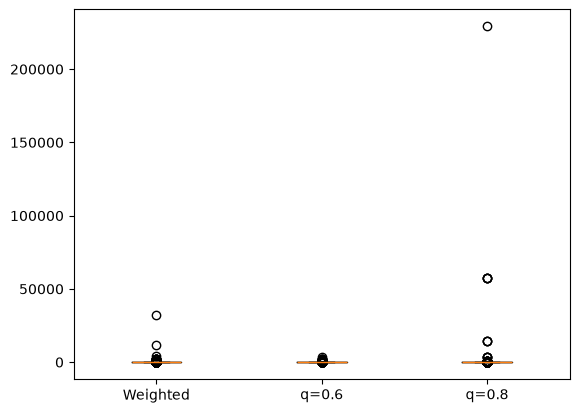

In [275]:
import matplotlib.pyplot as plt
plt.boxplot(
    [weighteds, arbitrary_q1, arbitrary_q2],
    tick_labels=['Weighted', 'q=0.6', 'q=0.8']
)
plt.show()


In [276]:
print(np.mean(weighteds))
print(np.mean(arbitrary_q1))
print(np.mean(arbitrary_q2))




82.65827346316449
59.27659338119407
529.9233746637916


In [278]:
# Under the null the e values' mean must be leq 1
n=100
tau=0.5
theta=0.4
weighteds=[weighted_eval(n=n,tau=tau,theta=theta,K=10) for _ in range(1000)]
S_ns=[np.random.binomial(n,theta) for _ in range(1000)]
arbitrary_q1=[compute_eval(n=n,q=0.6,S_n=S_ns[i], tau=tau) for i in range(1000)]
arbitrary_q2=[compute_eval(n=n,q=0.8,S_n=S_ns[i], tau=tau) for i in range(1000)]
print(np.mean(weighteds))
print(np.mean(arbitrary_q1))
print(np.mean(arbitrary_q2))


0.11145829269107481
0.01752888800900421
1.2650040242086242e-09


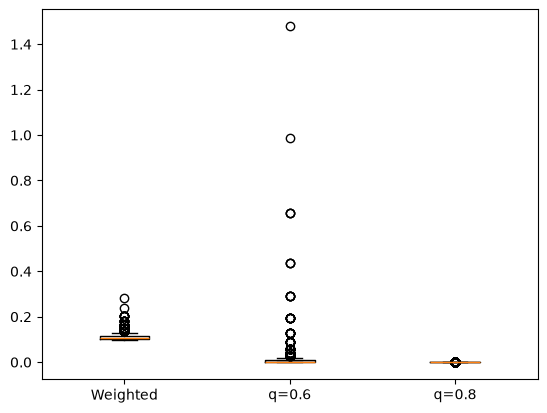

In [279]:
import matplotlib.pyplot as plt
plt.boxplot(
    [weighteds, arbitrary_q1, arbitrary_q2],
    tick_labels=['Weighted', 'q=0.6', 'q=0.8']
)
plt.show()


In [280]:
#define a weighted p-value that takes certian inputsso we dont generate them
# inefficiently in the sequential approach
q_grid=np.linspace(tau+0.0001, 0.999, 10)
S_n=np.random.binomial(n,theta)
def weighted_eval_aux(n,tau,S_n,q_grid):
    total=0
    for q in q_grid:
        total=total+compute_eval(n=n,q=q,S_n=S_n, tau=tau)
    return total/len(q_grid)

In [315]:
def sequential_test_mine(budget, tau, theta,alpha):
    q_grid=np.linspace(tau+0.0001, 0.999, 10)
    obtained_evalues=[]
    S_n=0
    n_aux=1
    while budget>0:
        #generate a Bernoulli outcome and add it to the sequential sum
        S_n=S_n+np.random.binomial(1,theta)
        budget=budget-1#budget gets reduced every time we generate a rollout of the Bernoulli experiment
        obtain_evalue=weighted_eval_aux(n_aux,tau,S_n,q_grid)
        obtained_evalues.append(obtain_evalue)
        if  obtain_evalue>1/alpha:
            return 1, n_aux, obtained_evalues
        n_aux+=1#keep counting the number of generated Bernoullis so far
    return [0]#  if we exit the while loop it measn we never rejected the null







    

$S_n=S_{n-1}+X_n=\sum_{i=1}^nX_i.$ is what we do in the while loop

In [323]:
sequential_test_mine(budget=200, tau=0.5, theta=0.6,alpha=.05)

(1,
 11,
 [1.4990999999999999,
  0.6494949933333334,
  0.8724362753933332,
  1.2140123657011763,
  1.7477729424144197,
  2.5972075763790445,
  3.9717432175928513,
  6.229809864832517,
  9.98997872334275,
  16.32787659734751,
  27.12681496057801])

$\mathbb{P}_{\theta=0.5}\left(\exists n\leq200:E_n^{\mathrm{mix}}\geq20\right)\leq0.05.$

In [324]:
sequential_test_mine(budget=200, tau=0.5, theta=0.6,alpha=.05)


[0]

In [326]:
sequential_test_mine(budget=200, tau=0.5, theta=0.6,alpha=.05)

(1,
 86,
 [1.4990999999999999,
  2.348705006666667,
  3.82497373794,
  6.435935110178823,
  11.124097277943227,
  2.5972075763790445,
  3.9717432175928513,
  6.229809864832517,
  2.4696410063222833,
  3.652080849337986,
  5.528938234117022,
  2.509232340944347,
  3.629423607738538,
  1.8962149691284758,
  1.1462556550312186,
  0.7702802107165626,
  0.9803945911579417,
  1.2730527176763773,
  1.685866125871882,
  1.096331142920233,
  1.4233393628852946,
  0.9650413414213096,
  1.2319014348585853,
  1.5998621531047488,
  1.0868726941191333,
  0.7838343918258115,
  0.5940563604002769,
  0.7188734318297435,
  0.5547998609614384,
  0.6651731593025071,
  0.8088665656813653,
  0.6200593493938091,
  0.7472853817588723,
  0.912936165794808,
  0.6953376841210436,
  0.8421578718623332,
  0.6509590387299193,
  0.519679661536303,
  0.6126275926861452,
  0.7309146833995988,
  0.8826306882573564,
  1.0787613204948032,
  1.3343184839955675,
  0.9986939853361886,
  1.2256972083810447,
  0.9298116563163

In [331]:
sequential_test_mine(budget=200, tau=0.5, theta=0.6,alpha=.05)

(1,
 182,
 [0.5009000000000001,
  0.3523050066666667,
  0.4265537112733333,
  0.5308601850854903,
  0.6802517889879331,
  0.898338308449795,
  0.5740046817343525,
  0.7316672999772893,
  0.5056224655704915,
  0.3830218256793894,
  0.4572673488689758,
  0.5571431359348662,
  0.42089816967277593,
  0.3368873141234744,
  0.39233934713170315,
  0.4646771959083413,
  0.5601658302751834,
  0.43259519591086076,
  0.5152336197981391,
  0.40631976355476496,
  0.4789720291278554,
  0.384339553766679,
  0.3196513465393287,
  0.3656337426324117,
  0.30743266565923905,
  0.3494865528255616,
  0.40230981237093755,
  0.46923928897081046,
  0.5547998609614384,
  0.6651731593025071,
  0.8088665656813653,
  0.9976737819689223,
  1.2480621821789724,
  1.5831881985631362,
  2.0358417496577004,
  2.652772076240589,
  3.5010780113263023,
  4.677698734408812,
  3.0318138275165976,
  2.061417703019726,
  1.4629369015871503,
  1.0787613204948032,
  0.8232041569940393,
  0.64771432865189,
  0.523737895012448,
 

In [368]:
sequential_test_mine(budget=200, tau=0.5, theta=0.6,alpha=.05)[0]

1

In [388]:
sequential_test_mine(budget=100, tau=0.5, theta=0.6,alpha=.05)[0]


0

In [358]:
sequential_test_mine(budget=200, tau=0.5, theta=0.45,alpha=.05)# would be extremely rare to see a wrong rejection
#since the null H0:theta\leq tau is true

[0]

0

In [328]:
sequential_test_mine(budget=200,tau=0.5,theta=0.4,alpha=0.05)

[0]

In [332]:
results = [sequential_test_mine(budget=200,tau=0.5,theta=0.4,alpha=0.05)[0] for _ in range(1000)]
print(np.mean(results))

0.003


In [333]:
results = [sequential_test_mine(budget=200,tau=0.5,theta=0.4,alpha=0.05)[0] for _ in range(1000)]
print(np.mean(results))

0.003


In [ ]:
total_rejections = [sequential_test_mine(budget=50,tau=0.4,theta=0.7,alpha=0.05)[0] for _ in range(1000)]
print(f'Power is {np.mean(total_rejections)}') #Probability of rejedcting the null when it is true

Power is 0.957


In [421]:
total_rejections = [sequential_test_mine(budget=50,tau=0.4,theta=0.6,alpha=0.05)[0] for _ in range(1000)]
print(f'Power is {np.mean(total_rejections)}')

Power is 0.605


# Power analysis and comparisons to binomial p-values

In [426]:
total_rejections = [sequential_test_mine(budget=50,tau=0.4,theta=0.6,alpha=0.05)[0] for _ in range(1000)]
powers={}
taus=[0.3+0.05*i for i in range(10)]
print(taus)
for tau in taus:
    total_rejections = [sequential_test_mine(budget=50,tau=tau,theta=0.5,alpha=0.05)[0] for _ in range(1000)]
    powers[tau]=np.mean(total_rejections)



[0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6000000000000001, 0.65, 0.7, 0.75]


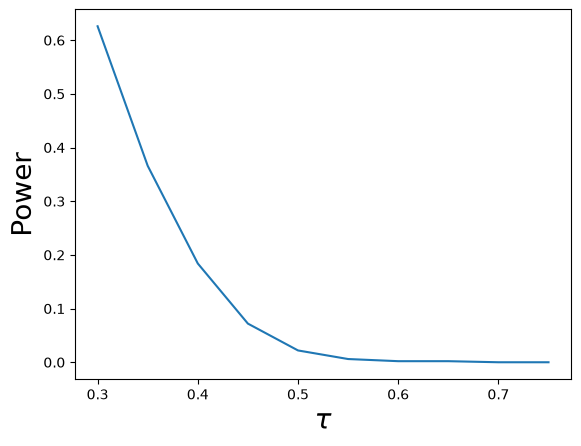

In [427]:
plt.plot(taus, powers.values())
plt.xlabel(r'$\tau$', fontsize=20)
plt.ylabel('Power', fontsize=20)
plt.show()

In [428]:
powers_2={}#now let's give more budget and twe should get more power# now a budget of 100
taus=[0.3+0.05*i for i in range(10)]
print(taus)
for tau in taus:
    total_rejections = [sequential_test_mine(budget=100,tau=tau,theta=0.5,alpha=0.05)[0] for _ in range(1000)]
    powers_2[tau]=np.mean(total_rejections)


[0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6000000000000001, 0.65, 0.7, 0.75]


In [431]:
powers_3={}#now let's give more budget and twe should get more power# now a budget of 200
taus=[0.3+0.05*i for i in range(10)]
print(taus)
for tau in taus:
    total_rejections = [sequential_test_mine(budget=200,tau=tau,theta=0.5,alpha=0.05)[0] for _ in range(1000)]
    powers_3[tau]=np.mean(total_rejections)


[0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6000000000000001, 0.65, 0.7, 0.75]


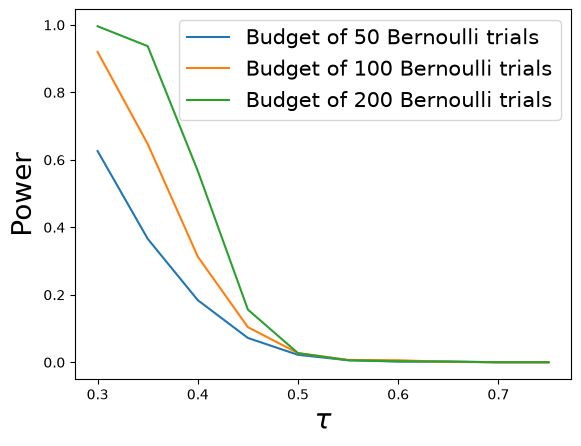

In [ ]:
plt.plot(taus, powers.values(), label='Budget of 50 Bernoulli trials')
plt.plot(taus, powers_2.values(), label='Budget of 100 Bernoulli trials')
plt.plot(taus, powers_3.values(), label='Budget of 200 Bernoulli trials')
plt.xlabel(r'$\tau$', fontsize=20)
plt.ylabel('Power', fontsize=20)
plt.legend(fontsize=15)
plt.show()

In [ ]:
#remember with LE Nieto we saw how large n's converge to the ideal power :) which equals one on the alternative region
#and zero on the null region. #remember the power is the probability of rejecting the null

In [433]:
compute_evalue(n=100,theta_1=0.8,tau=.5, theta=0.8)

917399.4463960276

# Compare power in the simple e-value case

In [605]:
theta_1s=[0.45+0.05*i for i in range(10)]
print(theta_1s)

[0.45, 0.5, 0.55, 0.6000000000000001, 0.65, 0.7, 0.75, 0.8, 0.8500000000000001, 0.9]


In [606]:
powers={}
for theta_1 in theta_1s:
    print(theta_1)
    powers[theta_1]=[]#create empty list to store the obtained powers
    for _ in range(100):
        rejections=[compute_evalue(n=20,theta_1=theta_1,tau=.5, theta=0.8)>1/0.05 for _ in range(1000)]
        powers[theta_1].append(sum(rejections)/1000)

0.45
0.5
0.55
0.6000000000000001
0.65
0.7
0.75
0.8
0.8500000000000001
0.9


In [607]:
powers2={}
for theta_1 in theta_1s:
    print(theta_1)
    powers2[theta_1]=[]#create empty list to store the obtained powers
    for _ in range(100):
        rejections=[compute_evalue(n=50,theta_1=theta_1,tau=.5, theta=0.8)>1/0.05 for _ in range(1000)]
        powers2[theta_1].append(sum(rejections)/1000)

0.45
0.5
0.55
0.6000000000000001
0.65
0.7
0.75
0.8
0.8500000000000001
0.9


In [608]:
powers3={}
for theta_1 in theta_1s:
    print(theta_1)
    powers3[theta_1]=[]#create empty list to store the obtained powers
    for _ in range(100):
        rejections=[compute_evalue(n=100,theta_1=theta_1,tau=.5, theta=0.8)>1/0.05 for _ in range(1000)]
        powers3[theta_1].append(sum(rejections)/1000)

0.45
0.5
0.55
0.6000000000000001
0.65
0.7
0.75
0.8
0.8500000000000001
0.9


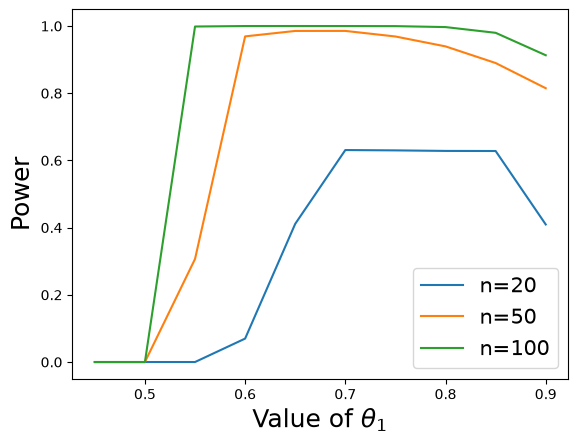

In [610]:
plt.plot(theta_1s, [np.mean(powers[theta_1]) for theta_1 in theta_1s], label='n=20')
plt.plot(theta_1s, [np.mean(powers2[theta_1]) for theta_1 in theta_1s], label='n=50')
plt.plot(theta_1s, [np.mean(powers3[theta_1]) for theta_1 in theta_1s], label='n=100')
plt.xlabel(r'Value of $\theta_1$', fontsize=18)
plt.legend(fontsize=15)
plt.ylabel('Power', fontsize=18)
plt.show()

# Comparing power to a p-value approach

In [695]:
from scipy.stats import binom

In [696]:
p_val_rejections=[]
tau=0.5
for i in range(100):
    direct_counts = np.random.binomial(n=50, p=0.7)
    p_vals_direct = binom.sf(direct_counts - 1, 50, tau)
    p_val_rejections.append(p_vals_direct<=0.05)
print(np.mean(p_val_rejections))

0.89


In [697]:
total_rejections = [sequential_test_mine(budget=50,tau=0.5,theta=0.7,alpha=0.05)[0] for _ in range(100)]
np.mean(total_rejections)


0.58

In [699]:
sequential_test_mine(budget=50,tau=0.5,theta=0.7,alpha=0.05)

(1,
 7,
 [1.4990999999999999,
  2.348705006666667,
  3.82497373794,
  6.435935110178823,
  11.124097277943227,
  19.650986979507408,
  35.33023074142197])

In [700]:
np.random.seed(123)
sequential_test_mine(budget=50,tau=0.5,theta=0.7,alpha=0.05)


(1,
 21,
 [1.4990999999999999,
  2.348705006666667,
  3.82497373794,
  6.435935110178823,
  1.7477729424144197,
  2.5972075763790445,
  1.2226719351652375,
  1.7136765703531853,
  2.4696410063222833,
  3.652080849337986,
  5.528938234117022,
  2.509232340944347,
  3.629423607738538,
  5.3626322463486,
  8.079090209471468,
  3.770117467105591,
  5.476167326677374,
  8.097252155963512,
  12.170205443016425,
  18.567214257035186,
  28.71549811083682])

In [701]:
np.random.seed(1123)
sequential_test_mine(budget=50,tau=0.5,theta=0.7,alpha=0.05)


[0]

In [708]:
budgets=[20,50,100,150,200]
tau=0.5
theta=0.7# Hence the null H0:theta<=tau is false. Hence it makes sense to study the power:
#prob of rejecting the null
power_p_values=[]
power_e_values=[]
average_used_budget=[]
for B in budgets:
    #run power simulaitons of p-value approach
    B_power=[]
    for i in range(100):
        direct_counts = np.random.binomial(n=B, p=theta)
        p_vals_direct = binom.sf(direct_counts - 1, B, tau)
        B_power.append(p_vals_direct<=0.05)
    power_p_values.append(np.mean(B_power))
    #run e-value simulations
    used_budget=[]
    rejections_evalues=np.zeros(100)
    for i in range(100):
        outcome=sequential_test_mine(budget=B,tau=tau,theta=theta,alpha=0.05)
        if outcome[0]==1:
            rejections_evalues[i]=1#register the rejected null
            used_budget.append(outcome[1])#register with how many iid Bernoulli experiments we were able to reject
        else:
            used_budget.append(B)# we used all our available budget in this trial with B iid Bernoullis
    average_used_budget.append(np.mean(used_budget))
    power_e_values.append(np.mean(rejections_evalues))




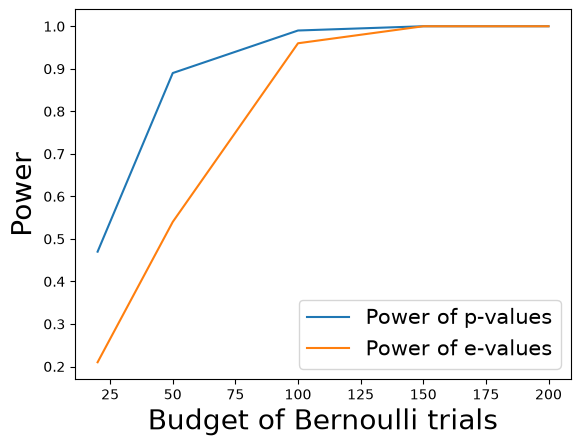

In [709]:
plt.plot(budgets, power_p_values, label='Power of p-values')
plt.plot(budgets, power_e_values, label='Power of e-values')
plt.legend(fontsize=15)
plt.xlabel('Budget of Bernoulli trials', fontsize=20)
plt.ylabel('Power', fontsize=20)
plt.show()

Text(0, 0.5, 'Avareage number of Bernoulli trials')

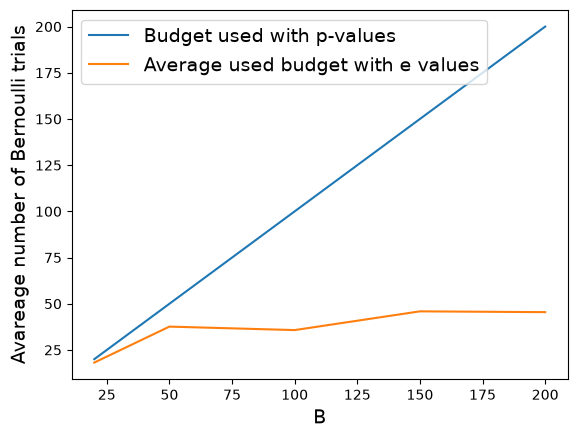

In [714]:
plt.plot(budgets,budgets,label='Budget used with p-values')
plt.plot(budgets, average_used_budget,label='Average used budget with e values')
plt.legend(fontsize=14)
plt.xlabel('B', fontsize=14)
plt.ylabel('Avareage number of Bernoulli trials', fontsize=14)



# This experiment gives us a very intereststing observation about p-values and how they compare to e-values:




### First, for small sample sizes (small budget) we can clearly appreciate that p-values are more powerful than e-values. But once we are given a sufficiently generous budget (eg. from B=100 onwards) we can appreciate that the advantage of e-values really starts to become observable: we get essentially the same power as p-values, but we require substantially less. The e-value approach requires on average somethign like 30 Bernoullis to reach the same power as the p-value formulation which is using more than 100 Bernoulli trials. In that sense the e-values allow for budget/cost aware, and data dependent rigorous decision making 